/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/trainer.py:86: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


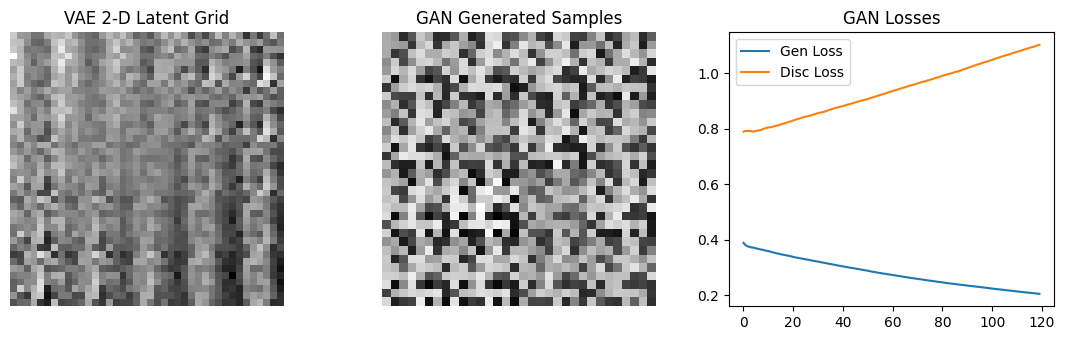

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import load_digits
from tensorflow.keras import layers, models, ops

x_data = (load_digits().data[:800] / 16.0).astype("float32")

# Encoder
enc_in = layers.Input(shape=(64,))
h = layers.Dense(32, activation="relu")(enc_in)
z_mean = layers.Dense(2)(h)
z_log_var = layers.Dense(2)(h)
encoder = models.Model(enc_in, [z_mean, z_log_var])

# Decoder
dec_in = layers.Input(shape=(2,))
dec_out = layers.Dense(64, activation="sigmoid")(dec_in)
decoder = models.Model(dec_in, dec_out)

vae_opt = tf.keras.optimizers.Adam(1e-3)
batch_size = 64

for epoch in range(25):
    idx = np.random.permutation(len(x_data))
    for start in range(0, len(x_data), batch_size):
        xb = x_data[idx[start:start + batch_size]]
        with tf.GradientTape() as tape:
            zm, zlv = encoder(xb, training=True)
            eps = tf.random.normal(shape=tf.shape(zm), dtype=zm.dtype)
            z_samp = zm + tf.exp(0.5 * zlv) * eps
            recon = decoder(z_samp, training=True)
            recon_loss = ops.mean(ops.sum(ops.square(xb - recon), axis=1))
            kl_loss = -0.5 * ops.mean(ops.sum(1 + zlv - ops.square(zm) - ops.exp(zlv), axis=1))
            loss = recon_loss + 0.01 * kl_loss
        trainable_vars = encoder.trainable_weights + decoder.trainable_weights
        grads = tape.gradient(loss, trainable_vars)
        vae_opt.apply_gradients(zip(grads, trainable_vars))

# Quick GAN
gen = models.Sequential([
    layers.Input(shape=(8,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(64, activation="sigmoid")
])
disc = models.Sequential([
    layers.Input(shape=(64,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])
disc.compile(optimizer="adam", loss="binary_crossentropy")
disc.trainable = False
gan = models.Sequential([gen, disc])
gan.compile(optimizer="adam", loss="binary_crossentropy")

g_losses, d_losses = [], []
for _ in range(120):
    b_idx = np.random.randint(0, len(x_data), 32)
    real = x_data[b_idx]
    noise = np.random.normal(size=(32, 8)).astype("float32")
    fake = gen.predict(noise, verbose=0)
    d_l = disc.train_on_batch(np.vstack([real, fake]), np.array([1]*32 + [0]*32, dtype="float32"))
    g_l = gan.train_on_batch(np.random.normal(size=(32, 8)).astype("float32"), np.ones((32, 1), dtype="float32"))
    d_losses.append(float(np.mean(d_l)))
    g_losses.append(float(np.mean(g_l)))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
grid_z = np.array([[i, j] for i in np.linspace(-1.5, 1.5, 5) for j in np.linspace(-1.5, 1.5, 5)], dtype="float32")
vae_imgs = decoder.predict(grid_z, verbose=0).reshape(5, 5, 8, 8).transpose(0, 2, 1, 3).reshape(40, 40)
axes[0].imshow(vae_imgs, cmap="gray")
axes[0].set_title("VAE 2-D Latent Grid")
axes[0].axis("off")

fake_imgs = gen.predict(np.random.normal(size=(16, 8)).astype("float32"), verbose=0).reshape(4, 4, 8, 8).transpose(0, 2, 1, 3).reshape(32, 32)
axes[1].imshow(fake_imgs, cmap="gray")
axes[1].set_title("GAN Generated Samples")
axes[1].axis("off")

axes[2].plot(g_losses, label="Gen Loss")
axes[2].plot(d_losses, label="Disc Loss")
axes[2].set_title("GAN Losses")
axes[2].legend()
plt.tight_layout()
plt.show()